In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/473.JPG
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/1031.JPG
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/333.JPG
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/94.png
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/785.JPG
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/48.png
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/539.JPG
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/61.png
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/815.JPG
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/37.png
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs/182.JPG
/k

In [6]:
os.listdir(ROOT)

['OPGs', 'annotations']

/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/OPGs
/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db/dataset/annotations
Total pairs: 250

================ SPLIT SUMMARY ================
Train: 175
Val  : 37
Test : 38
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 193MB/s]



🚀 Starting Training...



Epoch 1/10 [Train]: 100%|██████████| 88/88 [00:33<00:00,  2.60it/s, loss=0.173]



📊 Epoch 1/10
Train Loss : 0.3007
Val Loss   : 0.1497
Val Dice   : 0.8435
Val IoU    : 0.7305


...


📊 Epoch 8/10
Train Loss : 0.0647
Val Loss   : 0.0723
Val Dice   : 0.9253
Val IoU    : 0.8615


Epoch 9/10 [Train]: 100%|██████████| 88/88 [00:31<00:00,  2.80it/s, loss=0.0467]



📊 Epoch 9/10
Train Loss : 0.0594
Val Loss   : 0.0660
Val Dice   : 0.9323
Val IoU    : 0.8736


Epoch 10/10 [Train]: 100%|██████████| 88/88 [00:31<00:00,  2.81it/s, loss=0.0467]



📊 Epoch 10/10
Train Loss : 0.0528
Val Loss   : 0.0666
Val Dice   : 0.9314
Val IoU    : 0.8719

================ FINAL TEST RESULTS ================
Test Dice : 0.9326
Test IoU  : 0.8744


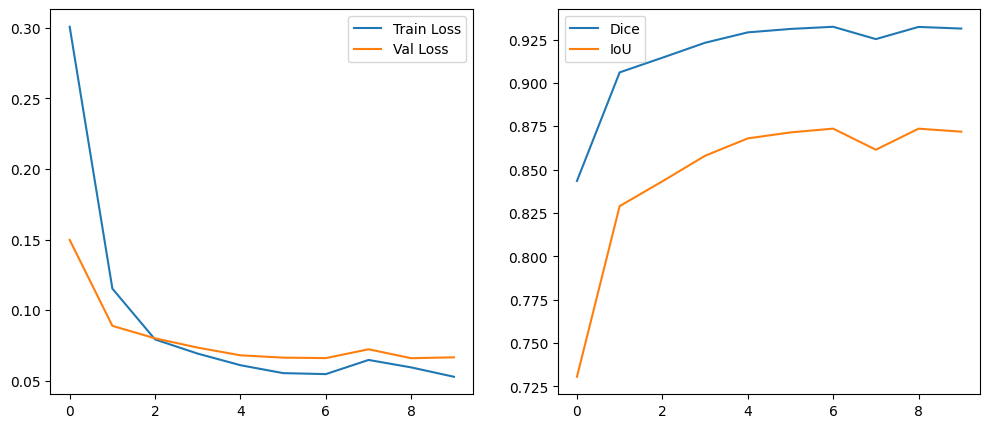

In [11]:
import os
import json
import cv2
import numpy as np
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# ============================================================
# 1. ROOT
# ============================================================
ROOT = "/kaggle/input/datasets/boulesnane/niihhaa/CAP_Niihhaa-Dataset-4ac91db"
IMG_SIZE = (640, 1280)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ============================================================
# 2. BUILD PAIRS
# ============================================================
pairs = []

for folder in os.listdir(ROOT):

    folder_path = os.path.join(ROOT, folder)
    if not os.path.isdir(folder_path):
        continue

    img_dir = os.path.join(folder_path, "OPGs")
    ann_dir = os.path.join(folder_path, "annotations")
    print(img_dir)
    print(ann_dir)
    if not os.path.exists(ann_dir):
        ann_dir = os.path.join(folder_path, "annnotations")

    if not os.path.exists(img_dir) or not os.path.exists(ann_dir):
        continue

    for img_name in os.listdir(img_dir):

        if not img_name.lower().endswith((".png", ".jpg")):
            continue

        stem = os.path.splitext(img_name)[0]

        img_path = os.path.join(img_dir, img_name)
        json_path = os.path.join(ann_dir, stem + ".json")

        if os.path.exists(json_path):
            pairs.append((img_path, json_path))

print("Total pairs:", len(pairs))

# ============================================================
# 3. SPLIT BY UNIQUE IDS
# ============================================================
def get_id(pair):
    return os.path.basename(pair[0]).split(".")[0]

all_ids = list(set(get_id(p) for p in pairs))

np.random.seed(42)
np.random.shuffle(all_ids)

n = len(all_ids)
train_ids = set(all_ids[:int(0.7*n)])
val_ids   = set(all_ids[int(0.7*n):int(0.85*n)])
test_ids  = set(all_ids[int(0.85*n):])

def filter_pairs(ids):
    return [p for p in pairs if get_id(p) in ids]

train_pairs = filter_pairs(train_ids)
val_pairs   = filter_pairs(val_ids)
test_pairs  = filter_pairs(test_ids)

print("\n================ SPLIT SUMMARY ================")
print("Train:", len(train_pairs))
print("Val  :", len(val_pairs))
print("Test :", len(test_pairs))

# ============================================================
# 4. DATASET
# ============================================================
class NiihhaaDataset(Dataset):

    def __init__(self, pairs):
        self.pairs = pairs

    def polygon_to_mask(self, pts, h, w):
        mask = np.zeros((h, w), dtype=np.uint8)
        pts = np.array(pts, dtype=np.int32)
        cv2.fillPoly(mask, [pts], 1)
        return mask

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):

        img_path, json_path = self.pairs[idx]

        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        h, w = img.shape[:2]

        with open(json_path) as f:
            data = json.load(f)

        mask = np.zeros((h, w), dtype=np.uint8)

        for s in data.get("shapes", []):
            if s.get("shape_type") != "polygon":
                continue

            pts = s.get("points", None)
            if pts is None:
                continue

            mask = np.maximum(mask, self.polygon_to_mask(pts, h, w))

        img = cv2.resize(img, (IMG_SIZE[1], IMG_SIZE[0]))
        mask = cv2.resize(mask, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_NEAREST)

        img = torch.tensor(img).permute(2,0,1).float() / 255.0
        mask = torch.tensor(mask).unsqueeze(0).float()

        return img, mask

# ============================================================
# 5. DATALOADERS
# ============================================================
train_loader = DataLoader(NiihhaaDataset(train_pairs), batch_size=2, shuffle=True)
val_loader   = DataLoader(NiihhaaDataset(val_pairs), batch_size=2, shuffle=False)
test_loader  = DataLoader(NiihhaaDataset(test_pairs), batch_size=2, shuffle=False)

# ============================================================
# 6. MODEL
# ============================================================
class UNetResNet(nn.Module):

    def __init__(self):
        super().__init__()

        resnet = models.resnet34(weights=models.ResNet34_Weights.DEFAULT)

        self.enc1 = nn.Sequential(resnet.conv1, resnet.bn1, resnet.relu)
        self.enc2 = nn.Sequential(resnet.maxpool, resnet.layer1)
        self.enc3 = resnet.layer2
        self.enc4 = resnet.layer3
        self.enc5 = resnet.layer4

        self.up4 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec4 = nn.Conv2d(512, 256, 3, padding=1)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = nn.Conv2d(256, 128, 3, padding=1)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec2 = nn.Conv2d(128, 64, 3, padding=1)

        self.up1 = nn.ConvTranspose2d(64, 64, 2, 2)
        self.dec1 = nn.Conv2d(128, 64, 3, padding=1)

        self.final = nn.Conv2d(64, 1, 1)

    def forward(self, x):

        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        e5 = self.enc5(e4)

        d4 = self.up4(e5)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))

        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        out = self.final(d1)

        out = F.interpolate(out, size=(IMG_SIZE[0], IMG_SIZE[1]),
                            mode="bilinear", align_corners=False)

        return out

model = UNetResNet().to(device)

# ============================================================
# 7. LOSS
# ============================================================
bce = nn.BCEWithLogitsLoss()

class DiceLoss(nn.Module):
    def forward(self, pred, target):

        pred = torch.sigmoid(pred)

        pred = pred.view(pred.size(0), -1)
        target = target.view(target.size(0), -1)

        inter = (pred * target).sum(1)

        dice = (2 * inter + 1e-6) / (pred.sum(1) + target.sum(1) + 1e-6)

        return 1 - dice.mean()

dice_loss = DiceLoss()

def loss_fn(pred, target):
    return 0.5 * bce(pred, target) + 0.5 * dice_loss(pred, target)

# ============================================================
# 8. METRICS
# ============================================================
def dice_score(pred, target):

    pred = (torch.sigmoid(pred) > 0.5).float()
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    inter = (pred * target).sum(1)

    return (2 * inter / (pred.sum(1) + target.sum(1) + 1e-6)).mean().item()


def iou_score(pred, target):

    pred = (torch.sigmoid(pred) > 0.5).float()
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    inter = (pred * target).sum(1)
    union = (pred + target - pred * target).sum(1)

    return (inter / (union + 1e-6)).mean().item()

# ============================================================
# 9. TRAINING
# ============================================================
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
epochs = 10

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}

print("\n🚀 Starting Training...\n")

for epoch in range(epochs):

    model.train()
    train_loss = 0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")

    for imgs, masks in loop:

        imgs, masks = imgs.to(device), masks.to(device)

        preds = model(imgs)
        loss = loss_fn(preds, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    train_loss /= len(train_loader)

    model.eval()

    val_loss = 0
    val_dice = 0
    val_iou = 0

    with torch.no_grad():
        for imgs, masks in val_loader:

            imgs, masks = imgs.to(device), masks.to(device)

            preds = model(imgs)

            val_loss += loss_fn(preds, masks).item()
            val_dice += dice_score(preds, masks)
            val_iou += iou_score(preds, masks)

    val_loss /= len(val_loader)
    val_dice /= len(val_loader)
    val_iou  /= len(val_loader)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_iou)

    print(f"\n📊 Epoch {epoch+1}/{epochs}")
    print(f"Train Loss : {train_loss:.4f}")
    print(f"Val Loss   : {val_loss:.4f}")
    print(f"Val Dice   : {val_dice:.4f}")
    print(f"Val IoU    : {val_iou:.4f}")

# ============================================================
# 10. TEST
# ============================================================
model.eval()

test_dice = 0
test_iou = 0

with torch.no_grad():
    for imgs, masks in test_loader:

        imgs, masks = imgs.to(device), masks.to(device)

        preds = model(imgs)

        test_dice += dice_score(preds, masks)
        test_iou += iou_score(preds, masks)

print("\n================ FINAL TEST RESULTS ================")
print(f"Test Dice : {test_dice/len(test_loader):.4f}")
print(f"Test IoU  : {test_iou/len(test_loader):.4f}")



In [13]:
torch.save(model.state_dict(), "/kaggle/working/unet.pth")

In [14]:
import matplotlib.pyplot as plt
import torch
import numpy as np
import random

# model = UNetResNet().to(device)
# modell=model.load_state_dict(torch.load("/kaggle/working/unet_model.pth", map_location=device))
model.eval()

def show_test_prediction(model, dataset, idx=None, threshold=0.5):

    if idx is None:
        idx = random.randint(0, len(dataset)-1)

    img, mask = dataset[idx]

    img_in = img.unsqueeze(0).to(device)

    with torch.no_grad():
        pred = model(img_in)
        pred = torch.sigmoid(pred).cpu().squeeze().numpy()

    img_np = img.permute(1,2,0).numpy()
    mask_np = mask.squeeze().numpy()

    pred_bin = (pred > threshold).astype(np.uint8)


    plt.figure(figsize=(12,4))

    plt.subplot(1,4,1)
    plt.title("Test Image")
    plt.imshow(img_np)
    plt.axis("off")

    plt.subplot(1,4,2)
    plt.title("Ground Truth")
    plt.imshow(mask_np, cmap="gray")
    plt.axis("off")

    plt.subplot(1,4,3)
    plt.title("Prediction")
    plt.imshow(pred_bin, cmap="gray")
    plt.axis("off")

   

    plt.show()

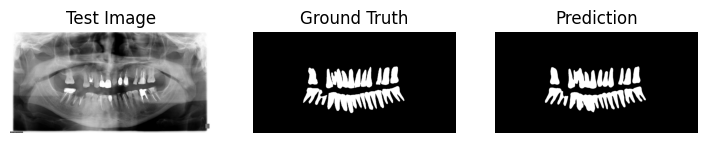

In [15]:
show_test_prediction(model,NiihhaaDataset(test_pairs),idx=30)